In [ ]:
print("Dataset shape:", df.shape) #give us numbers of rows and columns
#17379 rows and 17 columns
df.info()#give us information about the dataset like data types and null values

df.describe() # statistical summary of the dataset like mean, std, min, max, and percentiles

Dataset shape: (17379, 17)
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


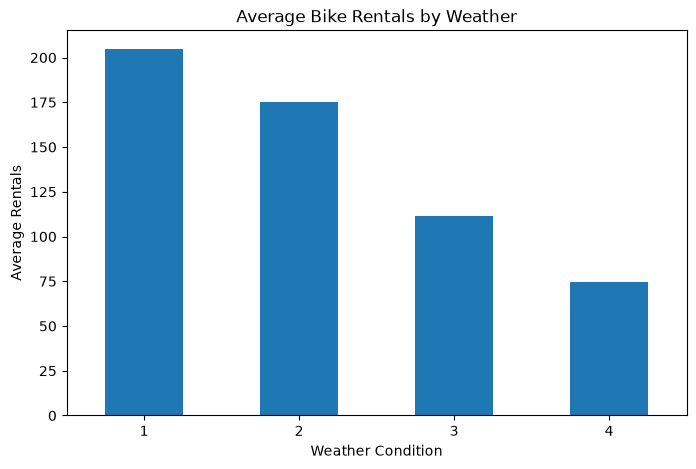

In [30]:
import matplotlib.pyplot as plt
weather_rentals = df.groupby("weathersit")["cnt"].mean()

weather_rentals.plot(kind="bar", figsize=(8,5))

plt.title("Average Bike Rentals by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
#1:Clear/Few Clouds, 2:Mist + Cloudy, 3:Light Snow/Rain, 4:Heavy Rain/Snow
plt.savefig("../images/rentals_by_weather.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

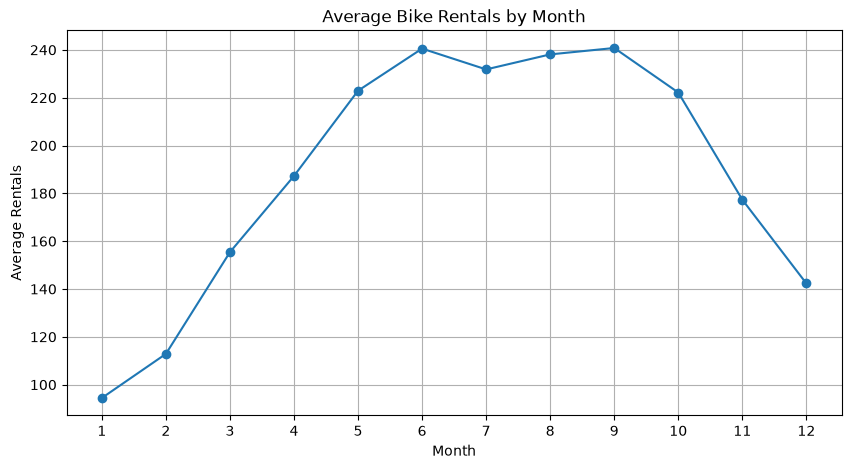

In [29]:
monthly_rentals = df.groupby("mnth")["cnt"].mean()

monthly_rentals.plot(kind="line", marker="o", figsize=(10,5))

plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.xticks(range(1, 13))
plt.grid()
plt.savefig("../images/rentals_by_month.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [10]:
df["day_type"] = df["weekday"].apply(
    lambda day: "Weekend" if day in [0, 6] else "Weekday"
)

In [27]:
day_type_rentals = df.groupby("day_type")["cnt"].mean()

print(day_type_rentals)

day_type
Weekday    191.738374
Weekend    183.852014
Name: cnt, dtype: float64


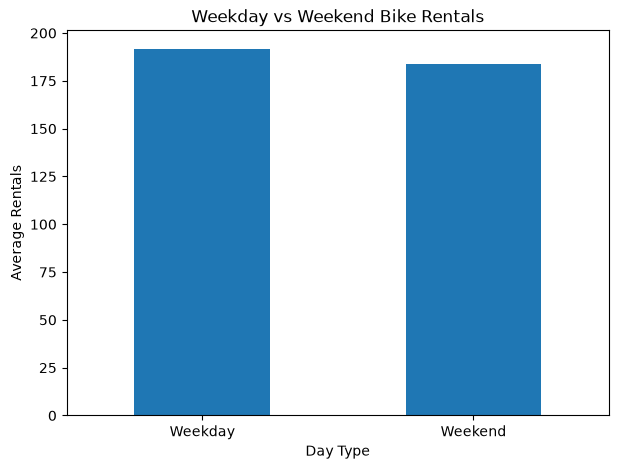

In [28]:
day_type_rentals.plot(kind="bar", figsize=(7,5))

plt.title("Weekday vs Weekend Bike Rentals")
plt.xlabel("Day Type")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.savefig("../images/weekday_vs_weekend.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [13]:
correlation = df[
    ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
].corr()

print(correlation)

                temp     atemp       hum  windspeed    casual  registered  \
temp        1.000000  0.987672 -0.069881  -0.023125  0.459616    0.335361   
atemp       0.987672  1.000000 -0.051918  -0.062336  0.454080    0.332559   
hum        -0.069881 -0.051918  1.000000  -0.290105 -0.347028   -0.273933   
windspeed  -0.023125 -0.062336 -0.290105   1.000000  0.090287    0.082321   
casual      0.459616  0.454080 -0.347028   0.090287  1.000000    0.506618   
registered  0.335361  0.332559 -0.273933   0.082321  0.506618    1.000000   
cnt         0.404772  0.400929 -0.322911   0.093234  0.694564    0.972151   

                 cnt  
temp        0.404772  
atemp       0.400929  
hum        -0.322911  
windspeed   0.093234  
casual      0.694564  
registered  0.972151  
cnt         1.000000  


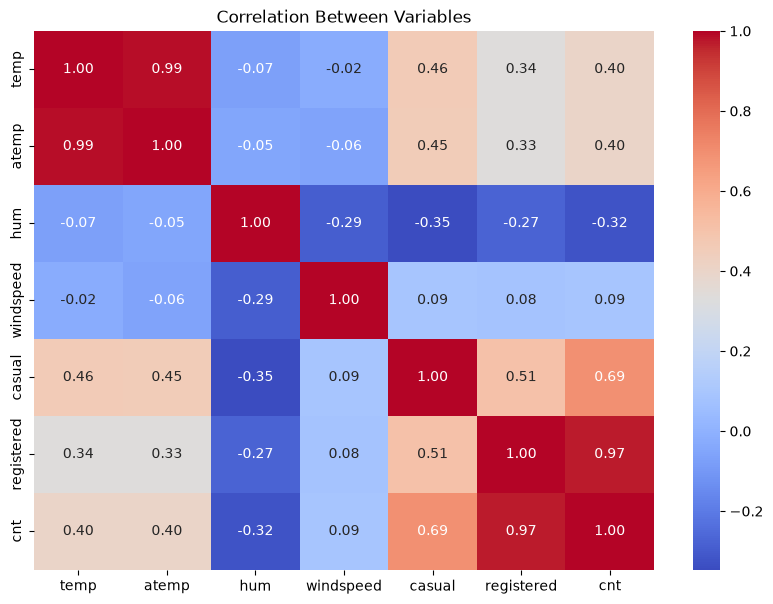

In [ ]:
import seaborn as sns
plt.figure(figsize=(10,7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Variables")
plt.savefig("../images/correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()
#### Correlation Analysis Findings

The correlation analysis revealed several relationships between weather conditions and bike rental demand.

- Temperature has a moderate positive correlation with total bike rentals (0.40).
- Feeling temperature also has a moderate positive correlation with rentals (0.40).
- Humidity has a negative correlation with total rentals (-0.32).
- Windspeed has a very weak positive correlation with rentals (0.09).
- Registered users have a very strong correlation with total rentals (0.97), while casual users have a correlation of 0.69.

**Conclusion:** Temperature and humidity show noticeable relationships with bike rental demand. However, correlation does not imply causation. The strong correlation between registered users and total rentals is partly expected because registered users are included in the total count.

In [7]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

instant         int64
dteday            str
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

In [24]:
#season has the highest of bike rentals
season_rentals = df.groupby("season")["cnt"].sum()
print(season_rentals)

season
1     471348
2     918589
3    1061129
4     841613
Name: cnt, dtype: int64


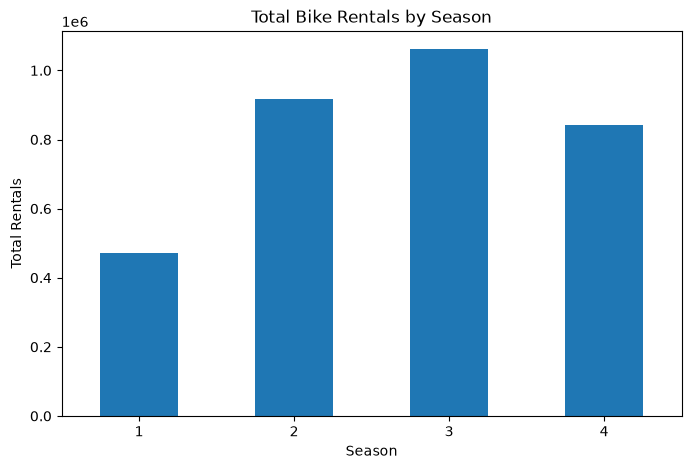

In [33]:
season_rentals.plot(kind="bar", figsize=(8,5)) #this will create a bar chart with the total bike rentals for each season.
#The x-axis will represent the seasons, and the y-axis will represent the total number of rentals.
# #The figsize parameter specifies the size of the plot.

plt.title("Total Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Total Rentals")
plt.xticks(rotation=0)#this will rotate the x-axis labels to be horizontal for better readability.
plt.savefig("../images/rentals_by_season.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()
#1:Winter, 2:Spring, 3:Summer, 4:Fall

In [21]:
hourly_rentals = df.groupby("hr")["cnt"].mean()
print(hourly_rentals)

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


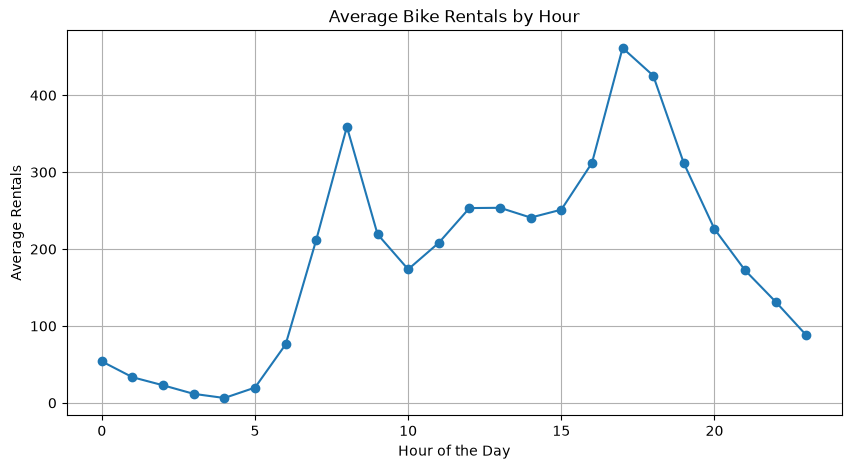

In [23]:
df["hr"] = df["hr"].astype(int)  # Ensure 'hr' is of integer type for proper plotting
hourly_rentals.plot(kind="line", figsize=(10,5), marker="o")

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Rentals")

plt.grid()
plt.savefig("../images/rentals_by_hour.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [34]:
peak_hour = df.groupby("hr")["cnt"].mean().idxmax()

peak_rentals = df.groupby("hr")["cnt"].mean().max()

print("Peak Hour:", peak_hour)
print("Average Rentals:", peak_rentals)

Peak Hour: 17
Average Rentals: 461.45205479452056


In [35]:
season_rentals = df.groupby("season")["cnt"].mean()

best_season = season_rentals.idxmax()

print("Best Season:", best_season)
print(season_rentals)

Best Season: 3
season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64


In [ ]:
weather_rentals = df.groupby("weathersit")["cnt"].mean()
#1:Clear/Few Clouds, 2:Mist + Cloudy, 3:Light Snow/Rain, 4:Heavy Rain/Snow
print(weather_rentals)

weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64


In [37]:
user_types = df[["casual", "registered"]].sum()

print(user_types)

print("Most Active User Type:", user_types.idxmax())

casual         620017
registered    2672662
dtype: int64
Most Active User Type: registered


In [38]:
# 1. Peak Hour
hourly_rentals = df.groupby("hr")["cnt"].mean()
peak_hour = hourly_rentals.idxmax()

# 2. Best Season
season_rentals = df.groupby("season")["cnt"].mean()
best_season = season_rentals.idxmax()

# 3. Best Weather Condition
weather_rentals = df.groupby("weathersit")["cnt"].mean()
best_weather = weather_rentals.idxmax()

# 4. User Types
user_types = df[["casual", "registered"]].sum()
most_active_user = user_types.idxmax()

# 5. Print Results
print("========== BUSINESS INSIGHTS ==========")

print("Peak Rental Hour:", peak_hour)
print("Best Season:", best_season)
print("Best Weather Condition:", best_weather)
print("Most Active User Type:", most_active_user)

print("\nAverage Rentals by Hour:")
print(hourly_rentals)

print("\nAverage Rentals by Season:")
print(season_rentals)

print("\nAverage Rentals by Weather:")
print(weather_rentals)

print("\nTotal Rentals by User Type:")
print(user_types)

========== BUSINESS INSIGHTS ==========
Peak Rental Hour: 17
Best Season: 3
Best Weather Condition: 1
Most Active User Type: registered

Average Rentals by Hour:
hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

Average Rentals by Season:
season
1    111.114569
2    208.344069
3    236.016237
4    198.868856
Name: cnt, dtype: float64

Average Rentals by Weather:
weathersit
1    204.869272
2    175.165493
3    111.579281
4     74.333333
Name: cnt, dtype: float64

Total Rentals by User Type:
casual         620017
registered    2672662
dtype: int64


In [45]:
from src.analysis import load_data
from src.analysis import rentals_by_season
from src.analysis import rentals_by_hour
from src.analysis import user_type_totals
from src.analysis import correlation_matrix
from src.analysis import get_business_insights

# Load dataset
df = load_data()

# Test functions
print("Rentals by Season:")
print(rentals_by_season(df))

print("\nRentals by Hour:")
print(rentals_by_hour(df))

print("\nUser Types:")
print(user_type_totals(df))

print("\nCorrelation:")
print(correlation_matrix(df))

print("\nBusiness Insights:")
print(get_business_insights(df))

Rentals by Season:
season
1     471348
2     918589
3    1061129
4     841613
Name: cnt, dtype: int64

Rentals by Hour:
hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

User Types:
casual         620017
registered    2672662
dtype: int64

Correlation:
                temp     atemp       hum  windspeed    casual  registered  \
temp        1.000000  0.987672 -0.069881  -0.023125  0.459616    0.335361   
atemp       0.987672  1.000000 -0.051918  -0.062336  0.454080    0.332559   
hum        -0.069881 -0.051918  1.000000  -0.290105 -0.347028   -0.273933   
windspeed  -0.023125 -0.062336 -0.290105   1.000000

In [41]:
import os

print(os.getcwd())

c:\Users\ZhuanZ\bike-sharing-data-analysis\notebooks


In [42]:
import sys
sys.path.append("..")

In [43]:
from src.analysis import load_data
from src.analysis import rentals_by_season
from src.analysis import rentals_by_hour
from src.analysis import user_type_totals
from src.analysis import correlation_matrix
from src.analysis import get_business_insights

In [44]:
df = load_data()

print(df.head())

print(get_business_insights(df))

   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  
{'peak_hour': np.int64(17), 'best_season': np.int64(3), 'best_weather': np.int64(1), 'most_active_u

In [19]:
user_types = df[["casual", "registered"]].sum()

print(user_types)

casual         620017
registered    2672662
dtype: int64


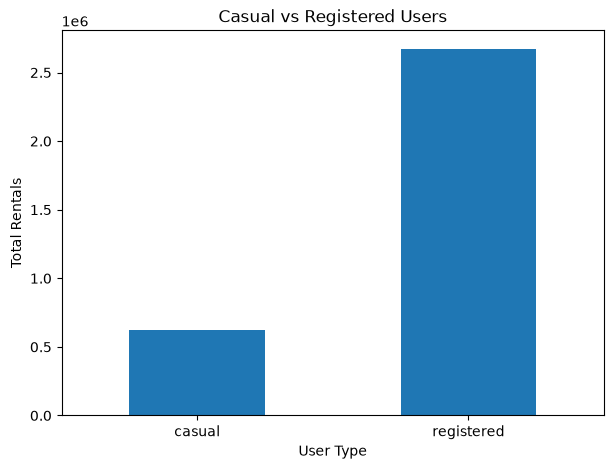

In [32]:
user_types.plot(kind="bar", figsize=(7,5))

plt.title("Casual vs Registered Users")
plt.xlabel("User Type")
plt.ylabel("Total Rentals")
plt.xticks(rotation=0)
plt.savefig("../images/casual_vs_registered.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

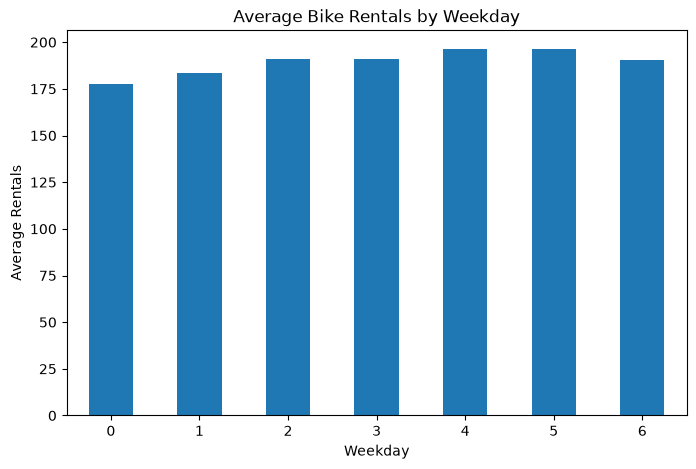

In [31]:
weekday_rentals = df.groupby("weekday")["cnt"].mean()

weekday_rentals.plot(kind="bar", figsize=(8,5))

plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Rentals")
plt.xticks(rotation=0)
plt.savefig("../images/rentals_by_weekday.png", dpi=300, bbox_inches="tight")
plt.show()
plt.show()

In [ ]:
import pandas as pd #ta3amol mea data analysis like read CSV files
import numpy as np #library used for numerical operations avereage Arrays and matrices
import matplotlib.pyplot as plt #library used for creating Graphs Bar chart Line chart Histogram etc
import seaborn as sns #help to create professionel Graphs and plots

# Load dataset
df = pd.read_csv("../data/hour.csv") #df=data frame table contain Rows and columns like Excel

# Display first 5 rows
df.head() 

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1
